## 08 - Raw Counts versus TPM: XDec Full-Pipeline Sensitivity and Sanity Checks

### Aim
* Test whether GDC STAR raw counts versus GDC TPM changes XDec Stage-1 proportions and Stage-2 expression, differential expression, and pathway conclusions under matched settings.

### Input
* Matched GDC count/TPM matrices; identical pre-exported reference files and informative genes; fixed k=3/8 and three paired random seeds; original Stage-2 sensitivity results.

### Output
* Separate timestamped results with Stage-1 profile matching, seed stability, reconstruction diagnostics, Stage-2 fixed-input and branch-specific comparisons, complete BH-adjusted DE tables, enrichment, figures, logs, and integrity manifests. Original results and XDec internals are preserved.

### Steps
* Validate and hash inputs; run paired Stage-1 fits; align profiles; compare proportions, reference/marker evidence, and reconstruction; run Stage 2 with branch-specific proportions and groups; compare DE/enrichment; verify saved files and selected independent NNLS solutions.

### Result
* Completed 12 matched Stage-1 fits (k=3/8; three seeds), 4 full-cohort Stage-2 fits, and 18 grouped Stage-2 comparisons. Median raw-count/TPM proportion Spearman correlations are 0.793 at k=3 and 0.856 at k=8; within-input seed medians exceed 0.99.
* In primary-seed end-to-end analyses, BH FDR < 0.05 yields 0/74/58 raw-count versus 0/5/168 TPM genes for the matched original Profile_2/5/8 anchors. These IDs do not establish cell-type identity.
* All 72 independent NNLS checks and 18 full BH-array checks passed; 144 enrichment outcomes were recorded without failures. Hashes verify 217 protected original files are unchanged.

### Conclusion
* Under these settings, raw counts and TPM are not interchangeable: observed Stage-1 input differences exceed seed variation and end-to-end DE outcomes change. This measures expression-unit sensitivity, not STAR-versus-RSEM quantification, the uniquely correct input unit, or independent biological validity.


### 1. Inputs, provenance, and execution settings

Both matrices have already been quantified by GDC. No external normalization is added; XDec handles its own Stage-1 preprocessing. Stage 0 is held fixed to isolate expression-unit effects. Commands use the unmodified XDec implementation and identical thread settings. Completed commands may be resumed only after checking their command record and output hashes.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import os, sys, json, hashlib, subprocess, time, itertools, platform
from concurrent.futures import ThreadPoolExecutor, as_completed
import numpy as np
import pandas as pd
from scipy.stats import spearmanr, norm
from scipy.optimize import linear_sum_assignment, nnls
from statsmodels.stats.multitest import multipletests
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

candidates=[Path.cwd(),*Path.cwd().parents]
PROGRESS=next(p for parent in candidates for p in (parent,parent/'progress') if (p/'workflow/Snakefile').is_file())
ROOT=PROGRESS.parent
RUN=PROGRESS/'data/deconvolution/sensitivity'/'full_pipeline_counts_vs_tpm_20261101_233117'
SOURCE=PROGRESS/'data/deconvolution/xdec'
OLD=PROGRESS/'data/deconvolution/sensitivity/stage2_tpm_20261031_122707'
XDEC=PROGRESS/'tools/XDec_SM/python/xdec.py'
INPUTS={'raw_counts':PROGRESS/'data/processed/TCGA-PAAD_counts_raw.tsv','TPM':PROGRESS/'data/processed/TCGA-PAAD_TPM_raw.tsv'}
REFS=SOURCE/'refs.tsv'; META=SOURCE/'ref_metadata.tsv'; PROBES=SOURCE/'stage0/selected_probes.txt'
SEEDS=[12345,12346,12347]; KS=[3,8]; PRIMARY_SEED=SEEDS[0]
MAX_ITS=2000; RSS_STOP=1e-10
# Unmodified XDec defaults, with identical BLAS thread limits for all jobs.
ENV=os.environ.copy()
ENV.update(OPENBLAS_NUM_THREADS='1',OMP_NUM_THREADS='1',MKL_NUM_THREADS='1',VECLIB_MAXIMUM_THREADS='1')

def sha(path):
 h=hashlib.sha256()
 with open(path,'rb') as f:
  for c in iter(lambda:f.read(2**20),b''):h.update(c)
 return h.hexdigest()

def write_new_json(path,obj):
 with open(path,'x') as f:json.dump(obj,f,indent=2)

RUN.mkdir(parents=True,exist_ok=True)
required=[*INPUTS.values(),REFS,META,PROBES,XDEC]
input_hashes={str(p.relative_to(ROOT)):sha(p) for p in required}
settings={'seeds':SEEDS,'k':KS,'max_its':MAX_ITS,'rss_stop':RSS_STOP,'reference_mode':'A: same pre-exported refs in both input branches','BLAS_threads':1,'stage0':'fixed existing probes, no reselection or k sweep'}
if not (RUN/'manifest.json').exists():
 protected=list(SOURCE.rglob('*'))+list(OLD.rglob('*'))
 protected_hashes={str(p.relative_to(ROOT)):sha(p) for p in protected if p.is_file()}
 write_new_json(RUN/'protected_original_sha256.json',protected_hashes)
 import importlib.metadata
 write_new_json(RUN/'manifest.json',{'created_utc':datetime.now(timezone.utc).isoformat(),'status':'running','inputs':input_hashes,'settings':settings,'python':sys.executable,'python_version':platform.python_version(),'packages':{p:importlib.metadata.version(p) for p in ['numpy','pandas','scipy','statsmodels','matplotlib']},'xdec_commit':subprocess.check_output(['git','-C',str(XDEC.parents[1]),'rev-parse','HEAD'],text=True).strip()})
else:
 m=json.loads((RUN/'manifest.json').read_text())
 assert m['inputs']==input_hashes and m['settings']==settings,'Inputs/settings changed; select a NEW RUN name'

bulk={u:pd.read_csv(p,sep='\t',index_col=0) for u,p in INPUTS.items()}
assert bulk['raw_counts'].index.equals(bulk['TPM'].index) and bulk['raw_counts'].columns.equals(bulk['TPM'].columns)
for u,b in bulk.items():assert b.index.is_unique and b.columns.is_unique and np.isfinite(b.values).all() and b.values.min()>=0
samples=bulk['TPM'].columns
probes=[g.strip() for g in PROBES.read_text().splitlines() if g.strip()]
assert len(probes)==len(set(probes))

def checked_command(cmd,outdir):
 """Resume only a command with a matching manifest and intact output hashes."""
 outdir=Path(outdir); marker=outdir/'command_complete.json'
 if marker.exists():
  done=json.loads(marker.read_text());assert done['argv']==cmd
  assert all(sha(outdir/f)==v for f,v in done['sha256'].items())
  return {**done,'reused':True}
 assert not outdir.exists(),f'Partial/unrecognized output exists: {outdir}; choose a new RUN'
 outdir.mkdir(parents=True)
 t=time.time()
 with open(outdir/'command.log','x') as log:
  result=subprocess.run(cmd,cwd=PROGRESS,env=ENV,stdout=log,stderr=subprocess.STDOUT)
 if result.returncode:raise RuntimeError(f'Command failed ({result.returncode}): {outdir}/command.log')
 done={'argv':cmd,'elapsed_seconds':time.time()-t,'sha256':{p.name:sha(p) for p in outdir.glob('*.tsv')},'returncode':result.returncode}
 assert done['sha256'],f'No tables produced: {outdir}'
 write_new_json(marker,done)
 return {**done,'reused':False}

print('Run:',RUN)
print('Input matrices:',{u:b.shape for u,b in bulk.items()})
print('Fixed k:',KS,'Seeds:',SEEDS,'Informative genes:',len(probes))


/Users/liruixi/.matplotlib is not a writable directory
Matplotlib created a temporary cache directory at /var/folders/zm/3lz9flfj09bckkt8msbyw9lh0000gn/T/matplotlib-suootd7q because there was an issue with the default path (/Users/liruixi/.matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.
Matplotlib is building the font cache; this may take a moment.
Run: /Users/liruixi/Desktop/i20_transfer/QCB/rotation/Alex/XDec_Pancreatic_Cancer/progress/data/deconvolution/sensitivity/full_pipeline_counts_vs_tpm_20261101_233117
Input matrices: {'raw_counts': (59427, 182), 'TPM': (59427, 182)}
Fixed k: [3, 8] Seeds: [12345, 12346, 12347] Informative genes: 344


### 2. Paired Stage-1 runs

Run k=3 and k=8 for three identical seeds in each branch (12 fits). The same reference TSVs are used for joint normalization and post-hoc correlations in both branches. At most two jobs run concurrently. Fixed-k comparisons do not replace the original k sweep or estimate optimal k anew.

In [2]:
def stage1_dir(unit,k,seed):return RUN/'stage1'/unit/f'k{k}'/f'seed{seed}'
def fit_stage1(job):
 unit,k,seed=job;out=stage1_dir(unit,k,seed)
 cmd=[sys.executable,str(XDEC),'stage1','--bulk',str(INPUTS[unit]),'--refs',str(REFS),'--ref-metadata',str(META),'--probes',str(PROBES),'--k',str(k),'--seed',str(seed),'--max-its',str(MAX_ITS),'--rss-stop',str(RSS_STOP),'--outdir',str(out)]
 record=checked_command(cmd,out)
 p=pd.read_csv(out/'proportions.tsv',sep='\t',index_col=0)
 m=pd.read_csv(out/'cell_type_profiles.tsv',sep='\t',index_col=0)
 assert p.index.equals(samples) and p.shape==(len(samples),k)
 assert np.isfinite(p.values).all() and p.values.min()>=0 and np.allclose(p.sum(axis=1),1)
 assert np.isfinite(m.values).all() and m.values.min()>=0
 print('Stage 1 completed:',unit,'k',k,'seed',seed,round(record['elapsed_seconds'],1),'seconds',flush=True)
 return {'input':unit,'k':k,'seed':seed,**record}
jobs=list(itertools.product(INPUTS,KS,SEEDS))
with ThreadPoolExecutor(max_workers=2) as executor:
 stage1_records=[f.result() for f in as_completed([executor.submit(fit_stage1,j) for j in jobs])]
pd.DataFrame([{k:v for k,v in r.items() if k not in ['argv','sha256']} for r in stage1_records]).to_csv(RUN/'stage1_execution_summary.tsv',sep='\t',index=False)
print('All',len(stage1_records),'Stage-1 fits completed.')


Stage 1 completed: raw_counts k 3 seed 12345 45.0 secondsStage 1 completed: raw_counts k 3 seed 12346 45.2 seconds

Stage 1 completed: raw_counts k 3 seed 12347 48.5 seconds
Stage 1 completed: raw_counts k 8 seed 12345 277.2 seconds
Stage 1 completed: raw_counts k 8 seed 12346 251.5 seconds
Stage 1 completed: TPM k 3 seed 12345 13.8 seconds
Stage 1 completed: raw_counts k 8 seed 12347 255.6 seconds
Stage 1 completed: TPM k 3 seed 12347 12.3 seconds
Stage 1 completed: TPM k 3 seed 12346 12.7 seconds
Stage 1 completed: TPM k Stage 1 completed: 8 seed 12346 143.4 seconds
TPM k 8 seed 12345 178.3 seconds
Stage 1 completed: TPM k 8 seed 12347 181.1 seconds
All 12 Stage-1 fits completed.


### 3. Profile alignment, proportions, seed stability, identity evidence, and reconstruction

Profile numbers are arbitrary. Use a global one-to-one Hungarian assignment over shared informative-gene expression patterns, then quantify matching ambiguity and compare with an alternative assignment from proportions. Canonical IDs refer to the primary raw-count fit. The original three profile IDs are traced to this fit instead of assuming they retain their old labels. Marker scores and reference correlations are descriptive evidence, not definitive identity calls. Recompute XDec's normalization solely to evaluate in-sample reconstruction; no external normalization is introduced.

In [3]:
import importlib.util
spec=importlib.util.spec_from_file_location('xdec_unmodified',XDEC)
xdec=importlib.util.module_from_spec(spec);spec.loader.exec_module(xdec)
print('Recomputing XDec normalization for reconstruction diagnostics (no fitting or edits).',flush=True)
ref_matrix=xdec.load_matrix(str(REFS))
normalized={u:xdec.normalise_bulk(xdec.load_matrix(str(INPUTS[u])),ref_matrix) for u in INPUTS}
del ref_matrix

def read_stage1(unit,k,seed):
 out=stage1_dir(unit,k,seed)
 return (pd.read_csv(out/'proportions.tsv',sep='\t',index_col=0),pd.read_csv(out/'cell_type_profiles.tsv',sep='\t',index_col=0))

def match_profiles(reference,other,genes):
 common=[g for g in genes if g in reference.index and g in other.index]
 assert len(common)>=10
 cross=pd.DataFrame(index=reference.columns,columns=other.columns,dtype=float)
 for a in reference:
  for b in other:
   r=spearmanr(reference.loc[common,a],other.loc[common,b]).statistic
   cross.loc[a,b]=r if np.isfinite(r) else -1.
 rows,cols=linear_sum_assignment(-cross.values)
 mapping={cross.index[i]:cross.columns[j] for i,j in zip(rows,cols)}
 diagnostics=[]
 for a,b in mapping.items():
  alternatives=cross.loc[a].drop(b)
  diagnostics.append({'canonical_profile':a,'matched_profile':b,'profile_spearman':cross.loc[a,b],
      'best_alternative_correlation':alternatives.max(),'assignment_margin':cross.loc[a,b]-alternatives.max(),
      'weak_match':bool(cross.loc[a,b]<.5 or cross.loc[a,b]-alternatives.max()<=0),'matching_genes':len(common)})
 return mapping,pd.DataFrame(diagnostics),cross

canonical={k:read_stage1('raw_counts',k,PRIMARY_SEED) for k in KS}
aligned={};mapping_rows=[];reference_rows=[];marker_rows=[];reconstruction=[]
marker_sets={'CAF':['COL1A1','COL1A2','DCN','LUM','ACTA2'],
 'Lymphocyte':['CD3D','CD3E','TRAC','CD79A','MS4A1','CD37','PTPRC'],
 'Enteroendocrine':['CHGA','CHGB','SYP','NEUROD1','TPH1']}
for unit,k,seed in jobs:
 p,m=read_stage1(unit,k,seed)
 mapping,diagnostics,cross=match_profiles(canonical[k][1],m,probes)
 diagnostics=diagnostics.assign(input=unit,k=k,seed=seed)
 mapping_rows.append(diagnostics)
 renamer={actual:canon for canon,actual in mapping.items()}
 ap=p.rename(columns=renamer)[canonical[k][0].columns]
 am=m.rename(columns=renamer)[canonical[k][1].columns]
 aligned[(unit,k,seed)]=(ap,am)
 dest=RUN/'aligned_stage1'/unit/f'k{k}'/f'seed{seed}';dest.mkdir(parents=True,exist_ok=True)
 ap.to_csv(dest/'proportions.tsv',sep='\t');am.to_csv(dest/'cell_type_profiles.tsv',sep='\t')
 cross.to_csv(dest/'matching_correlations.tsv',sep='\t')
 corr=pd.read_csv(stage1_dir(unit,k,seed)/'correlation.tsv',sep='\t',index_col=0).rename(columns=renamer)
 corr.to_csv(dest/'reference_correlations.tsv',sep='\t')
 for profile in ap:
  ordered=corr[profile].sort_values(ascending=False)
  reference_rows.append({'input':unit,'k':k,'seed':seed,'canonical_profile':profile,'top_reference':ordered.index[0],
    'top_reference_r':ordered.iloc[0],'second_reference':ordered.index[1],'second_reference_r':ordered.iloc[1],
    'reference_margin':ordered.iloc[0]-ordered.iloc[1]})
 for label,genes in marker_sets.items():
  present=[g for g in genes if g in am.index]
  scaled=am.loc[present].div(am.loc[present].max(axis=1).replace(0,np.nan),axis=0)
  for profile in am:
   marker_rows.append({'input':unit,'k':k,'seed':seed,'canonical_profile':profile,'marker_set':label,
     'relative_marker_score':scaled[profile].mean(),'available_markers':','.join(present),'n_markers':len(present)})
 b=normalized[unit].loc[m.index,samples].values
 residual=b-m.values@p.loc[samples].values.T
 selected=[i for i,g in enumerate(m.index) if g in set(probes)]
 for scope,idx in [('all_normalized_genes',np.arange(len(m))),('informative_genes',np.array(selected))]:
  value=b[idx];err=residual[idx];rss=float(np.square(err).sum());tss=float(np.square(value-value.mean(axis=1,keepdims=True)).sum())
  reconstruction.append({'input':unit,'k':k,'seed':seed,'scope':scope,'genes':len(idx),'RSS':rss,
       'RMSE':float(np.sqrt(np.mean(err**2))),'relative_RMSE':float(np.sqrt(np.sum(err**2)/np.sum(value**2))),
       'centered_R2':1-rss/tss if tss else np.nan})
map_table=pd.concat(mapping_rows,ignore_index=True);map_table.to_csv(RUN/'profile_matching.tsv',sep='\t',index=False)
pd.DataFrame(reference_rows).to_csv(RUN/'reference_identity_evidence.tsv',sep='\t',index=False)
pd.DataFrame(marker_rows).to_csv(RUN/'marker_identity_evidence.tsv',sep='\t',index=False)
pd.DataFrame(reconstruction).to_csv(RUN/'reconstruction_diagnostics.tsv',sep='\t',index=False)

# Align the three profiles previously interpreted biologically to the new canonical fit.
old_m=pd.read_csv(SOURCE/'stage1_with_refs_k8/cell_type_profiles.tsv',sep='\t',index_col=0)
old_to_canonical,old_diag,_=match_profiles(old_m,canonical[8][1],probes)
old_diag.rename(columns={'canonical_profile':'original_profile','matched_profile':'canonical_profile'}).to_csv(RUN/'original_to_new_profile_mapping.tsv',sep='\t',index=False)
ANCHORS={old:old_to_canonical[old] for old in ['Profile_2','Profile_5','Profile_8']}
write_new_json(RUN/'analysis_profile_anchors.json',ANCHORS) if not (RUN/'analysis_profile_anchors.json').exists() else None

comparisons=[];stability=[];group_overlap=[]
for k in KS:
 for seed in SEEDS:
  a,b=aligned[('raw_counts',k,seed)][0],aligned[('TPM',k,seed)][0]
  # Report an alternate assignment based on sample proportions as an ambiguity diagnostic.
  _,_,pcross=match_profiles(a,b,list(a.index))
  rr,cc=linear_sum_assignment(-pcross.values);alt={pcross.index[i]:pcross.columns[j] for i,j in zip(rr,cc)}
  for profile in a:
   x,y=a[profile],b[profile]
   comparisons.append({'k':k,'seed':seed,'canonical_profile':profile,'pearson_r':x.corr(y),
     'spearman_r':x.corr(y,method='spearman'),'MAE':abs(x-y).mean(),'max_abs_difference':abs(x-y).max(),
     'raw_mean':x.mean(),'TPM_mean':y.mean(),'proportion_based_match':alt[profile],
     'matching_methods_agree':alt[profile]==profile})
 for unit in INPUTS:
  for s1,s2 in itertools.combinations(SEEDS,2):
   a,b=aligned[(unit,k,s1)][0],aligned[(unit,k,s2)][0]
   for profile in a:
    stability.append({'input':unit,'k':k,'seed_a':s1,'seed_b':s2,'canonical_profile':profile,
      'proportion_spearman':a[profile].corr(b[profile],method='spearman'),'MAE':abs(a[profile]-b[profile]).mean()})
pd.DataFrame(comparisons).to_csv(RUN/'stage1_input_concordance.tsv',sep='\t',index=False)
pd.DataFrame(stability).to_csv(RUN/'stage1_seed_stability.tsv',sep='\t',index=False)
common=normalized['raw_counts'].index.intersection(normalized['TPM'].index)
normalization_diagnostics=[]
for u in INPUTS:
 normalization_diagnostics.append({'input':u,'retained_genes':len(normalized[u]),'retained_probes':sum(g in normalized[u].index for g in probes),
     'shared_retained_genes':len(common),'unit_specific_retained_genes':len(normalized[u].index.difference(common))})
pd.DataFrame(normalization_diagnostics).to_csv(RUN/'normalization_diagnostics.tsv',sep='\t',index=False)
print('Input concordance summary:')
print(pd.DataFrame(comparisons).groupby('k')[['spearman_r','MAE']].agg(['median','min','max']).to_string())
print('Weak/nonunique profile assignments:',int(map_table.weak_match.sum()),'of',len(map_table))
print('Original-to-canonical anchors:',ANCHORS)
print('Marker/reference evidence is descriptive, not a definitive profile identity.')


Recomputing XDec normalization for reconstruction diagnostics (no fitting or edits).
23:45:33  INFO      Loaded /Users/liruixi/Desktop/i20_transfer/QCB/rotation/Alex/XDec_Pancreatic_Cancer/progress/data/deconvolution/xdec/refs.tsv: 16849 genes × 2748 samples
23:45:34  INFO      Loaded /Users/liruixi/Desktop/i20_transfer/QCB/rotation/Alex/XDec_Pancreatic_Cancer/progress/data/processed/TCGA-PAAD_counts_raw.tsv: 54603 genes × 182 samples
23:45:34  INFO      Joint normalisation over 16755 shared genes (bulk + refs)
23:45:37  INFO      After normalisation: 16742 expressed genes × 182 bulk samples
23:45:37  INFO      Loaded /Users/liruixi/Desktop/i20_transfer/QCB/rotation/Alex/XDec_Pancreatic_Cancer/progress/data/processed/TCGA-PAAD_TPM_raw.tsv: 54603 genes × 182 samples
23:45:37  INFO      Joint normalisation over 16755 shared genes (bulk + refs)
23:45:40  INFO      After normalisation: 16673 expressed genes × 182 bulk samples
Input concordance summary:
  spearman_r                         

### 4. Separate Stage-2 expression-input, proportion-input, and grouping effects

Keep the earlier Stage-2-only sensitivity analysis read only and reproduce its full p-value/BH arrays. The new primary-seed analysis crosses both expression units with both proportion estimates at fixed original groups; separate end-to-end runs use each branch's own groups. This avoids attributing a change in grouping to normalization alone. Inclusive quantiles are used unless cutoff ties require a documented deterministic rank split. All tests are saved and corrected before filtering. Approximate conditional z-tests do not propagate Stage-1/group-selection uncertainty.

In [4]:
# Stage-2 experiments separate expression-input, proportion-estimation, and grouping effects.
# 1) full-cohort expression at each k, using each branch's own primary-seed proportions;
# 2) a 2x2 expression/proportion-input comparison holding ORIGINAL groups fixed;
# 3) end-to-end primary-seed branches with their own proportions AND own groups.

def make_tertiles(series):
 series=series[[s.split('-')[3][:2]=='01' for s in series.index]]
 q1,q2=series.quantile([1/3,2/3]);low=series.index[series<=q1];high=series.index[series>=q2]
 method='quantile_inclusive'
 if len(set(low)&set(high)) or len(low)>np.ceil(len(series)/3) or len(high)>np.ceil(len(series)/3):
  ordered=series.sort_index().sort_values(kind='stable');n=int(np.ceil(len(series)/3))
  low,high=ordered.index[:n],ordered.index[-n:];method='rank_split_due_to_cutoff_ties'
 assert len(set(low)&set(high))==0
 meta=pd.DataFrame({'group':['low']*len(low)+['high']*len(high)},index=list(low)+list(high));meta.index.name='Sample_ID'
 return meta,{'q33':q1,'q67':q2,'n_low':len(low),'n_high':len(high),'method':method}

metadata_dir=RUN/'groups';metadata_dir.mkdir(exist_ok=True)
group_rows=[];overlap_rows=[];own_groups={}
for old,canonical_profile in ANCHORS.items():
 fixed=pd.read_csv(SOURCE/f'tertile_meta/{old}_tertile_meta.tsv',sep='\t',index_col=0)
 fixed.to_csv(metadata_dir/f'{old}_original_fixed.tsv',sep='\t')
 for unit in INPUTS:
  for seed in SEEDS:
   meta,info=make_tertiles(aligned[(unit,8,seed)][0][canonical_profile]);own_groups[(old,unit,seed)]=meta
   meta.to_csv(metadata_dir/f'{old}_{unit}_seed{seed}.tsv',sep='\t')
   group_rows.append({'original_profile':old,'canonical_profile':canonical_profile,'input':unit,'seed':seed,**info})
   for direction in ['low','high']:
    a=set(fixed.index[fixed.group==direction]);b=set(meta.index[meta.group==direction])
    overlap_rows.append({'original_profile':old,'comparison':'original_vs_branch','input':unit,'seed':seed,'group':direction,'intersection':len(a&b),'union':len(a|b),'jaccard':len(a&b)/len(a|b)})
 for seed in SEEDS:
  a,b=own_groups[(old,'raw_counts',seed)],own_groups[(old,'TPM',seed)]
  for direction in ['low','high']:
   aa=set(a.index[a.group==direction]);bb=set(b.index[b.group==direction])
   overlap_rows.append({'original_profile':old,'comparison':'raw_vs_TPM_branch','input':'both','seed':seed,'group':direction,'intersection':len(aa&bb),'union':len(aa|bb),'jaccard':len(aa&bb)/len(aa|bb)})
pd.DataFrame(group_rows).to_csv(RUN/'tertile_cutoffs_and_ties.tsv',sep='\t',index=False)
pd.DataFrame(overlap_rows).to_csv(RUN/'group_membership_overlap.tsv',sep='\t',index=False)

full_stage2=[]
for unit in INPUTS:
 for k in KS:
  out=RUN/'stage2_full_cohort'/unit/f'k{k}'
  prop=RUN/'aligned_stage1'/unit/f'k{k}'/f'seed{PRIMARY_SEED}'/'proportions.tsv'
  cmd=[sys.executable,str(XDEC),'stage2','--bulk-counts',str(INPUTS[unit]),'--proportions',str(prop),'--outdir',str(out)]
  checked_command(cmd,out)
  full_stage2.append({'input':unit,'k':k,'outdir':str(out)})

# Across-gene rank concordance is descriptive: TPM also adjusts gene length.
expression_rows=[]
for k in KS:
 a=pd.read_csv(RUN/'stage2_full_cohort/raw_counts'/f'k{k}'/'stage2_means.tsv',sep='\t',index_col=0)
 b=pd.read_csv(RUN/'stage2_full_cohort/TPM'/f'k{k}'/'stage2_means.tsv',sep='\t',index_col=0)
 shared=a.index.intersection(b.index)
 for col in a:
  expression_rows.append({'k':k,'canonical_profile':col,'shared_genes':len(shared),
   'expression_rank_spearman':a.loc[shared,col].corr(b.loc[shared,col],method='spearman'),
   'raw_fraction_zero':float(a.loc[shared,col].eq(0).mean()),'TPM_fraction_zero':float(b.loc[shared,col].eq(0).mean())})
pd.DataFrame(expression_rows).to_csv(RUN/'stage2_full_expression_concordance.tsv',sep='\t',index=False)

experiments=[]
for old,canonical_profile in ANCHORS.items():
 for expression_unit,proportion_unit in itertools.product(INPUTS,repeat=2):
  experiments.append({'experiment':f'fixedG_expr_{expression_unit}_props_{proportion_unit}_{old}',
    'group_mode':'original_fixed','original_profile':old,'canonical_profile':canonical_profile,
    'expression_unit':expression_unit,'proportion_unit':proportion_unit,'seed':PRIMARY_SEED,
    'metadata':str(metadata_dir/f'{old}_original_fixed.tsv')})
 for unit in INPUTS:
  experiments.append({'experiment':f'ownG_expr_{unit}_props_{unit}_{old}',
    'group_mode':'branch_specific','original_profile':old,'canonical_profile':canonical_profile,
    'expression_unit':unit,'proportion_unit':unit,'seed':PRIMARY_SEED,
    'metadata':str(metadata_dir/f'{old}_{unit}_seed{PRIMARY_SEED}.tsv')})

def calculate_de(means,errors,col):
 high,low=means[f'{col}_high'],means[f'{col}_low']
 denom=np.hypot(errors[f'{col}_high'],errors[f'{col}_low']);valid=denom>0
 z=pd.Series(np.nan,index=means.index);z.loc[valid]=(high[valid]-low[valid])/denom[valid]
 p=pd.Series(np.nan,index=means.index);p.loc[valid]=2*norm.sf(abs(z[valid]))
 q=pd.Series(np.nan,index=means.index);q.loc[valid]=multipletests(p[valid],method='fdr_bh')[1]
 d=pd.DataFrame({'mean_high':high,'mean_low':low,'stderr_high':errors[f'{col}_high'],'stderr_low':errors[f'{col}_low'],
    'z':z,'pval':p,'padj_BH':q,'log2fc':np.log2((high+1)/(low+1)),'test_status':np.where(valid,'tested','zero_standard_error')})
 d['FDR05']=d.padj_BH<.05;d['FDR05_5fold']=d.FDR05 & d.log2fc.abs().ge(np.log2(5))
 d['nominal05_5fold']=d.pval.lt(.05) & d.log2fc.abs().ge(np.log2(5));d.index.name='gene'
 return d

des={};de_rows=[];enrichment_jobs=[];solver_checks=[];design_rows=[]
for experiment in experiments:
 eid=experiment['experiment'];col=experiment['canonical_profile'];punit=experiment['proportion_unit'];unit=experiment['expression_unit']
 out=RUN/'stage2_tertiles'/eid
 prop=RUN/'aligned_stage1'/punit/'k8'/f'seed{PRIMARY_SEED}'/'proportions.tsv'
 cmd=[sys.executable,str(XDEC),'stage2','--bulk-counts',str(INPUTS[unit]),'--proportions',str(prop),
      '--metadata',experiment['metadata'],'--subtype-col','group','--outdir',str(out)]
 checked_command(cmd,out)
 means=pd.read_csv(out/'stage2_means.tsv',sep='\t',index_col=0);errors=pd.read_csv(out/'stage2_stderrs.tsv',sep='\t',index_col=0)
 assert means.index.equals(errors.index) and means.columns.equals(errors.columns)
 assert all(np.isfinite(v.values).all() and v.values.min()>=0 for v in [means,errors])
 d=calculate_de(means,errors,col);des[eid]=d
 dest=RUN/'differential_expression'/eid;dest.mkdir(parents=True,exist_ok=True)
 d.to_csv(dest/'all_genes.tsv',sep='\t')
 for rule in ['FDR05','FDR05_5fold','nominal05_5fold']:
  sub=d[d[rule]];sub.to_csv(dest/f'{rule}.tsv',sep='\t')
  de_rows.append({**experiment,'rule':rule,'tested_genes':int(d.pval.notna().sum()),'total':len(sub),
     'up_high':int(sub.log2fc.gt(0).sum()),'up_low':int(sub.log2fc.lt(0).sum())})
 universe=dest/'universe.txt';universe.write_text('\n'.join(d.index[d.pval.notna()])+'\n')
 # Both FDR-only (less pseudocount-sensitive) and FDR+effect enrichment are saved.
 for rule in ['FDR05','FDR05_5fold']:
  for direction,mask in [('UpInHigh',d.log2fc>0),('UpInLow',d.log2fc<0)]:
   genes=dest/f'{rule}_{direction}_genes.txt';genes.write_text('\n'.join(d.index[d[rule]&mask])+'\n')
   enrichment_jobs.append({**experiment,'rule':rule,'direction':direction,'genes':str(genes),'universe':str(universe)})
 # Independent scipy NNLS check: one immune and one housekeeping gene per group/experiment.
 group=pd.read_csv(experiment['metadata'],sep='\t',index_col=0);P=aligned[(punit,8,PRIMARY_SEED)][0]
 for label in ['low','high']:
  ids=group.index[group.group==label]
  design_rows.append({'experiment':eid,'group':label,'n_samples':len(ids),'rank':int(np.linalg.matrix_rank(P.loc[ids].values)),'condition_number':float(np.linalg.cond(P.loc[ids].values))})
  for gene in ['PTPRC','GAPDH']:
   expected,_=nnls(P.loc[ids].values,bulk[unit].loc[gene,ids].values)
   actual=means.loc[gene,[f'{p}_{label}' for p in P]].values
   assert np.allclose(expected,actual,rtol=1e-5,atol=1e-3),(eid,label,gene)
   solver_checks.append({'experiment':eid,'group':label,'gene':gene,'max_absolute_error':float(abs(expected-actual).max())})
 print('Stage 2 and DE completed:',eid,flush=True)
pd.DataFrame(experiments).to_csv(RUN/'stage2_experiment_design.tsv',sep='\t',index=False)
pd.DataFrame(de_rows).to_csv(RUN/'DE_summary.tsv',sep='\t',index=False)
pd.DataFrame(enrichment_jobs).to_csv(RUN/'enrichment_jobs.tsv',sep='\t',index=False)
pd.DataFrame(solver_checks).to_csv(RUN/'independent_solver_checks.tsv',sep='\t',index=False)
pd.DataFrame(design_rows).to_csv(RUN/'stage2_design_diagnostics.tsv',sep='\t',index=False)

# Revalidate the old Stage-2-only experiment, without changing it.
old_check_rows=[]
for old in ANCHORS:
 for unit,folder in [('raw_counts',SOURCE/f'stage2_tertile_{old}'),('TPM',OLD/'tpm_stage2'/f'tertile_{old}')]:
  a=calculate_de(pd.read_csv(folder/'stage2_means.tsv',sep='\t',index_col=0),pd.read_csv(folder/'stage2_stderrs.tsv',sep='\t',index_col=0),old)
  previous=pd.read_csv(OLD/'differential_expression'/unit/f'{old}_all_genes.tsv',sep='\t',index_col=0)
  assert a.index.equals(previous.index)
  for key in ['pval','padj_BH','log2fc']:np.testing.assert_allclose(a[key],previous[key],rtol=1e-10,atol=1e-14,equal_nan=True)
  old_check_rows.append({'profile':old,'input':unit,'FDR05':int(a.FDR05.sum()),'FDR05_5fold':int(a.FDR05_5fold.sum()),'verified':True})
pd.DataFrame(old_check_rows).to_csv(RUN/'previous_stage2_sensitivity_verified.tsv',sep='\t',index=False)

pair_rows=[]
for old in ANCHORS:
 comparisons=[('expression_effect_fixed_raw_P',f'fixedG_expr_raw_counts_props_raw_counts_{old}',f'fixedG_expr_TPM_props_raw_counts_{old}'),
   ('proportion_effect_fixed_count_expression',f'fixedG_expr_raw_counts_props_raw_counts_{old}',f'fixedG_expr_raw_counts_props_TPM_{old}'),
   ('both_inputs_fixed_original_groups',f'fixedG_expr_raw_counts_props_raw_counts_{old}',f'fixedG_expr_TPM_props_TPM_{old}'),
   ('full_end_to_end_own_groups',f'ownG_expr_raw_counts_props_raw_counts_{old}',f'ownG_expr_TPM_props_TPM_{old}')]
 for name,first,second in comparisons:
  a,b=des[first],des[second];shared=a.index.intersection(b.index)
  for rule in ['FDR05','FDR05_5fold']:
   aset,bset=set(a.index[a[rule]]),set(b.index[b[rule]]);joint=sorted(aset&bset);union=aset|bset
   pair_rows.append({'original_profile':old,'comparison':name,'rule':rule,'first_experiment':first,'second_experiment':second,
      'first_genes':len(aset),'second_genes':len(bset),'shared':len(joint),'union':len(union),
      'jaccard':len(joint)/len(union) if union else np.nan,
      'shared_direction_agreement':float(np.mean(np.sign(a.loc[joint].log2fc)==np.sign(b.loc[joint].log2fc))) if joint else np.nan,
      'log2fc_spearman':a.loc[shared].log2fc.corr(b.loc[shared].log2fc,method='spearman')})
pd.DataFrame(pair_rows).to_csv(RUN/'DE_pairwise_concordance.tsv',sep='\t',index=False)
print('Primary-seed end-to-end counts:')
print(pd.DataFrame(de_rows).query("group_mode == 'branch_specific' and rule == 'FDR05'")[['original_profile','canonical_profile','expression_unit','total','up_high','up_low']].to_string(index=False))
print('Independent NNLS checks passed:',len(solver_checks))


Stage 2 and DE completed: fixedG_expr_raw_counts_props_raw_counts_Profile_2
Stage 2 and DE completed: fixedG_expr_raw_counts_props_TPM_Profile_2
Stage 2 and DE completed: fixedG_expr_TPM_props_raw_counts_Profile_2
Stage 2 and DE completed: fixedG_expr_TPM_props_TPM_Profile_2
Stage 2 and DE completed: ownG_expr_raw_counts_props_raw_counts_Profile_2
Stage 2 and DE completed: ownG_expr_TPM_props_TPM_Profile_2
Stage 2 and DE completed: fixedG_expr_raw_counts_props_raw_counts_Profile_5
Stage 2 and DE completed: fixedG_expr_raw_counts_props_TPM_Profile_5
Stage 2 and DE completed: fixedG_expr_TPM_props_raw_counts_Profile_5
Stage 2 and DE completed: fixedG_expr_TPM_props_TPM_Profile_5
Stage 2 and DE completed: ownG_expr_raw_counts_props_raw_counts_Profile_5
Stage 2 and DE completed: ownG_expr_TPM_props_TPM_Profile_5
Stage 2 and DE completed: fixedG_expr_raw_counts_props_raw_counts_Profile_8
Stage 2 and DE completed: fixedG_expr_raw_counts_props_TPM_Profile_8
Stage 2 and DE completed: fixedG_ex

### 5. GO:BP and KEGG enrichment with explicit tested backgrounds

This Python cell writes and executes a self-contained R analysis through `Rscript`; the notebook remains executable with a Python kernel. R requires clusterProfiler and org.Hs.eg.db. Set RSCRIPT_BIN if Rscript is not on PATH. Use the previously saved KEGG snapshot offline, so annotation timing is held fixed. Both FDR-only and FDR-plus-fivefold gene lists are tested, with matched tested-gene backgrounds and explicit failed/skipped/empty outcomes. The cache only shares calculations whose foreground/background file hashes match.

In [5]:
# Use the previously saved KEGG snapshot, so old/new comparisons do not differ
# merely because pathway annotations were downloaded on different dates.
import shutil
R_BIN=os.environ.get('RSCRIPT_BIN') or shutil.which('Rscript')
assert R_BIN, 'Set RSCRIPT_BIN to an Rscript with clusterProfiler and org.Hs.eg.db'
KEGG_SNAPSHOT=OLD/'enrichment_attempt_2/KEGG_annotation_snapshot.rds'
assert KEGG_SNAPSHOT.is_file()
annotation_dir=RUN/'annotations';annotation_dir.mkdir(exist_ok=True)
local_snapshot=annotation_dir/KEGG_SNAPSHOT.name
if local_snapshot.exists():assert sha(local_snapshot)==sha(KEGG_SNAPSHOT)
else:shutil.copyfile(KEGG_SNAPSHOT,local_snapshot)
KEGG_SNAPSHOT=local_snapshot
R_CODE=r'''
suppressPackageStartupMessages({library(clusterProfiler);library(org.Hs.eg.db)})
args <- commandArgs(trailingOnly=TRUE)
run <- args[1]; snapshot <- args[2]
jobs <- read.delim(file.path(run,"enrichment_jobs.tsv"),check.names=FALSE)
kegg <- readRDS(snapshot)
out <- file.path(run,"enrichment")
dir.create(out,showWarnings=FALSE)
statuses <- list();map_cache <- new.env();result_cache <- new.env()
read_genes <- function(p) {x <- readLines(p,warn=FALSE);unique(x[nzchar(x)])}
map_ids <- function(path) {
 key <- unname(tools::md5sum(path))
 if(exists(key,map_cache,inherits=FALSE)) return(get(key,map_cache))
 x <- read_genes(path)
 if(length(x)==0) return(character())
 m <- suppressMessages(AnnotationDbi::select(org.Hs.eg.db,keys=x,keytype="SYMBOL",columns="ENTREZID"))
 ans <- unique(m$ENTREZID[!is.na(m$ENTREZID)]);assign(key,ans,map_cache);ans
}
for(i in seq_len(nrow(jobs))) {
 j <- jobs[i,];genes <- read_genes(j$genes);universe <- read_genes(j$universe)
 ids <- map_ids(j$genes);bg <- map_ids(j$universe)
 for(kind in c("GO_BP","KEGG")) {
  folder <- file.path(out,j$experiment,j$rule,j$direction);dir.create(folder,recursive=TRUE,showWarnings=FALSE)
  state <- "success";message <- "";nall <- 0;nsig <- 0
  if(length(genes)<5) {state <- "not_run_fewer_than_5_genes"} else {
   key <- paste(kind,unname(tools::md5sum(j$genes)),unname(tools::md5sum(j$universe)),sep="_")
   if(exists(key,result_cache,inherits=FALSE)) {
    cached <- get(key,result_cache);result <- cached$result;state <- cached$state;message <- cached$message
   } else {
    result <- tryCatch({
      if(kind=="GO_BP") enrichGO(gene=genes,universe=universe,OrgDb=org.Hs.eg.db,keyType="SYMBOL",ont="BP",pAdjustMethod="BH",pvalueCutoff=1,qvalueCutoff=1)
      else enricher(gene=ids,universe=bg,TERM2GENE=kegg$term2gene,TERM2NAME=kegg$term2name,pAdjustMethod="BH",pvalueCutoff=1,qvalueCutoff=1)
    },error=function(e) {state <<- "failed";message <<- conditionMessage(e);NULL})
    assign(key,list(result=result,state=state,message=message),result_cache)
   }
   if(state!="failed") {
    d <- if(is.null(result)) data.frame() else result@result
    nall <- nrow(d);sig <- if(nall) d[!is.na(d$p.adjust)&d$p.adjust<.05,,drop=FALSE] else d
    nsig <- nrow(sig)
    write.table(d,file.path(folder,paste0(kind,"_all_terms.tsv")),sep="\t",quote=FALSE,row.names=FALSE)
    write.table(sig,file.path(folder,paste0(kind,"_FDR05.tsv")),sep="\t",quote=FALSE,row.names=FALSE)
    if(nsig==0) state <- "success_no_significant_terms"
   }
  }
  statuses[[length(statuses)+1]] <- data.frame(experiment=j$experiment,original_profile=j$original_profile,canonical_profile=j$canonical_profile,group_mode=j$group_mode,expression_unit=j$expression_unit,proportion_unit=j$proportion_unit,rule=j$rule,direction=j$direction,analysis=kind,status=state,foreground_symbols=length(genes),foreground_entrez=length(ids),universe_symbols=length(universe),universe_entrez=length(bg),tested_terms=nall,significant_terms=nsig,message=message)
  write.table(do.call(rbind,statuses),file.path(out,"status.tsv"),sep="\t",quote=FALSE,row.names=FALSE)
 }
 cat("Enrichment",i,"/",nrow(jobs),j$experiment,j$rule,j$direction,"\n")
}
writeLines(capture.output(sessionInfo()),file.path(out,"R_sessionInfo.txt"))
if(any(vapply(statuses,function(x) x$status=="failed",logical(1)))) stop("Enrichment failures recorded; inspect status.tsv")
'''
support=RUN/'support';support.mkdir(exist_ok=True)
r_source=support/'enrichment.R'
if r_source.exists():assert r_source.read_text()==R_CODE
else:r_source.write_text(R_CODE)
output=RUN/'enrichment'
if not (output/'complete.json').exists():
 assert not output.exists(),'Partial enrichment exists; use a NEW RUN rather than overwriting it'
 with open(RUN/'enrichment.log','x') as log:
  completed=subprocess.run([R_BIN,str(r_source),str(RUN),str(KEGG_SNAPSHOT)],stdout=log,stderr=subprocess.STDOUT,cwd=PROGRESS)
 assert completed.returncode==0,f'Enrichment failed; see {RUN}/enrichment.log'
 status=pd.read_csv(output/'status.tsv',sep='\t')
 assert len(status)==2*len(enrichment_jobs) and not status.status.eq('failed').any()
 write_new_json(output/'complete.json',{'Rscript':R_BIN,'KEGG_source':str(KEGG_SNAPSHOT),'KEGG_sha256':sha(KEGG_SNAPSHOT),
      'R_code_sha256':sha(r_source),'status_sha256':sha(output/'status.tsv'),'n_status_records':len(status)})
else:
 complete=json.loads((output/'complete.json').read_text());assert complete['status_sha256']==sha(output/'status.tsv')
 status=pd.read_csv(output/'status.tsv',sep='\t')
print(status.groupby(['group_mode','rule','analysis','status']).size().to_string())

pathway_pairs=[]
pairs=pd.read_csv(RUN/'DE_pairwise_concordance.tsv',sep='\t')
for pair in pairs.itertuples():
 for direction in ['UpInHigh','UpInLow']:
  for kind in ['GO_BP','KEGG']:
   values=[];states=[]
   for experiment in [pair.first_experiment,pair.second_experiment]:
    s=status[(status.experiment==experiment)&(status.rule==pair.rule)&(status.direction==direction)&(status.analysis==kind)].iloc[0]
    states.append(s.status)
    if s.status.startswith('success'):
     path=output/experiment/pair.rule/direction/f'{kind}_FDR05.tsv'
     try:d=pd.read_csv(path,sep='\t')
     except pd.errors.EmptyDataError:d=pd.DataFrame()
     values.append(dict(zip(d.ID,d.Description)) if len(d) else {})
    else:values.append(None)
   a,b=values
   pathway_pairs.append({'original_profile':pair.original_profile,'comparison':pair.comparison,'rule':pair.rule,'direction':direction,'analysis':kind,
     'first_status':states[0],'second_status':states[1],
     'first_terms':len(a) if a is not None else np.nan,'second_terms':len(b) if b is not None else np.nan,
     'shared_terms_count':len(set(a)&set(b)) if a is not None and b is not None else np.nan,
     'shared_terms':'; '.join(a[k] for k in sorted(set(a)&set(b))) if a is not None and b is not None else ''})
pd.DataFrame(pathway_pairs).to_csv(RUN/'pathway_pairwise_concordance.tsv',sep='\t',index=False)
print('All enrichment outcomes explicitly recorded; cached KEGG annotation reused.')


group_mode       rule         analysis  status                      
branch_specific  FDR05        GO_BP     not_run_fewer_than_5_genes       7
                                        success                          4
                                        success_no_significant_terms     1
                              KEGG      not_run_fewer_than_5_genes       7
                                        success                          5
                 FDR05_5fold  GO_BP     not_run_fewer_than_5_genes       7
                                        success                          4
                                        success_no_significant_terms     1
                              KEGG      not_run_fewer_than_5_genes       7
                                        success                          5
original_fixed   FDR05        GO_BP     not_run_fewer_than_5_genes      16
                                        success                          8
                              K

### 6. Sanity checks, figures, and interpretation

Verify hashes for original artifacts and inputs, compare selected means with independent SciPy NNLS, recheck BH arrays and command outputs, and generate the summary and figures. Fixed k/genes isolate expression-input effects; this is not a complete optimization over k or a claim that TPM is the uniquely appropriate input.

In [6]:
# Recheck every protected original and explicit input before final reporting.
protected=json.loads((RUN/'protected_original_sha256.json').read_text())
assert all(sha(ROOT/p)==digest for p,digest in protected.items()),'An original artifact changed'
assert all(sha(ROOT/p)==digest for p,digest in input_hashes.items()),'An input changed'
assert len(stage1_records)==12 and len(experiments)==18 and len(solver_checks)==72
assert not status.status.eq('failed').any()
# Independently recalculate complete BH arrays from stored p-values.
for eid,d in des.items():
 valid=np.isfinite(d.pval);expected=multipletests(d.loc[valid,'pval'],method='fdr_bh')[1]
 np.testing.assert_allclose(expected,d.loc[valid,'padj_BH'],rtol=1e-12,atol=1e-14)
 assert d.index.is_unique
for record in stage1_records:
 out=Path(record['argv'][-1]);assert all(sha(out/f)==h for f,h in record['sha256'].items())
validation={'protected_original_files_verified':len(protected),'input_hashes_verified':len(input_hashes),'stage1_fits':len(stage1_records),
 'full_cohort_stage2_fits':len(full_stage2),'grouped_stage2_fits':len(experiments),'independent_NNLS_checks_passed':len(solver_checks),
 'full_BH_arrays_rechecked':len(des),'old_stage2_sensitivity_tables_rechecked':len(old_check_rows),
 'enrichment_records':len(status),'enrichment_failures':int(status.status.eq('failed').sum())}
(RUN/'validation_results.json').write_text(json.dumps(validation,indent=2))

stage1_compare=pd.read_csv(RUN/'stage1_input_concordance.tsv',sep='\t')
stability=pd.read_csv(RUN/'stage1_seed_stability.tsv',sep='\t')
reconstruction=pd.read_csv(RUN/'reconstruction_diagnostics.tsv',sep='\t')
fig,axes=plt.subplots(1,2,figsize=(11,4))
for ax,k in zip(axes,KS):
 sub=stage1_compare[stage1_compare.k==k]
 labels=sorted(sub.canonical_profile.unique())
 for i,profile in enumerate(labels):
  values=sub[sub.canonical_profile==profile].spearman_r
  ax.scatter([i]*len(values),values,s=25,alpha=.65)
 ax.set(xticks=range(len(labels)),xticklabels=labels,ylim=(-1.05,1.05),ylabel='Raw vs TPM proportion Spearman r',title=f'k={k}; three paired seeds')
 ax.tick_params(axis='x',rotation=45);ax.axhline(0,color='gray',lw=.5)
fig.tight_layout();fig.savefig(RUN/'stage1_proportion_concordance.png',dpi=160);plt.close(fig)
fig,axes=plt.subplots(2,4,figsize=(13,6))
a,b=aligned[('raw_counts',8,PRIMARY_SEED)][0],aligned[('TPM',8,PRIMARY_SEED)][0]
for ax,col in zip(axes.flat,a.columns):
 ax.scatter(a[col],b[col],s=9,alpha=.5);limit=max(a[col].max(),b[col].max());ax.plot([0,limit],[0,limit],color='gray',lw=.7)
 ax.set(xlabel='Raw-count branch proportion',ylabel='TPM branch proportion',title=col)
fig.suptitle('Matched k=8 profiles; primary seed; labels are canonical IDs')
fig.tight_layout();fig.savefig(RUN/'stage1_k8_scatter.png',dpi=160);plt.close(fig)

de_table=pd.read_csv(RUN/'DE_summary.tsv',sep='\t');pair_table=pd.read_csv(RUN/'DE_pairwise_concordance.tsv',sep='\t')
fig,axes=plt.subplots(2,2,figsize=(11,8))
for row,mode in enumerate(['original_fixed','branch_specific']):
 for column,rule in enumerate(['FDR05','FDR05_5fold']):
  ax=axes[row,column];x=np.arange(len(ANCHORS))
  for i,unit in enumerate(INPUTS):
   values=[int(de_table[(de_table.original_profile==old)&(de_table.expression_unit==unit)&(de_table.proportion_unit==unit)&(de_table.group_mode==mode)&(de_table.rule==rule)].total.iloc[0]) for old in ANCHORS]
   ax.bar(x+(i-.5)*.34,values,.34,label=unit)
   for pos,v in zip(x+(i-.5)*.34,values):ax.text(pos,v+.6,str(v),ha='center',fontsize=8)
  ax.set(xticks=x,xticklabels=list(ANCHORS),ylabel='DE genes',title=f'{mode}: {rule}');ax.legend(fontsize=8)
fig.suptitle('Both branches use their own primary-seed proportions; original profile IDs identify matched anchors')
fig.tight_layout();fig.savefig(RUN/'DE_count_comparison.png',dpi=160);plt.close(fig)
fig,axes=plt.subplots(1,3,figsize=(13,4))
for ax,old in zip(axes,ANCHORS):
 a=des[f'ownG_expr_raw_counts_props_raw_counts_{old}'];b=des[f'ownG_expr_TPM_props_TPM_{old}'];shared=a.index.intersection(b.index)
 ax.scatter(a.loc[shared].log2fc,b.loc[shared].log2fc,s=1,alpha=.12)
 ax.set(xlabel='Raw-count branch log2FC (+1)',ylabel='TPM branch log2FC (+1)',title=f'{old} anchor, own groups')
 ax.axhline(0,color='gray',lw=.5);ax.axvline(0,color='gray',lw=.5)
fig.tight_layout();fig.savefig(RUN/'end_to_end_effect_comparison.png',dpi=160);plt.close(fig)

# Compact tables require no optional markdown/table packages.
def markdown_table(frame):
 cols=list(frame.columns)
 def fmt(v):
  if isinstance(v,(float,np.floating)):return 'NA' if not np.isfinite(v) else f'{v:.4g}'
  return str(v).replace('|','/').replace('\n',' ')
 return '| '+' | '.join(cols)+' |\n| '+' | '.join(['---']*len(cols))+' |\n'+'\n'.join('| '+' | '.join(fmt(v) for v in row)+' |' for row in frame.itertuples(index=False,name=None))

primary=de_table[(de_table.group_mode=='branch_specific')&(de_table.rule.isin(['FDR05','FDR05_5fold']))][['original_profile','canonical_profile','expression_unit','rule','total','up_high','up_low']]
input_summary=stage1_compare.groupby('k').agg(median_proportion_r=('spearman_r','median'),min_proportion_r=('spearman_r','min'),max_proportion_r=('spearman_r','max'),median_MAE=('MAE','median')).reset_index()
seed_summary=stability.groupby(['input','k']).agg(median_seed_r=('proportion_spearman','median'),min_seed_r=('proportion_spearman','min'),median_MAE=('MAE','median')).reset_index()
primary_refs=pd.DataFrame(reference_rows).query('k == 8 and seed == @PRIMARY_SEED')
primary_refs=primary_refs[primary_refs.canonical_profile.isin(ANCHORS.values())][['input','canonical_profile','top_reference','top_reference_r','reference_margin']]
pathway_table=pd.read_csv(RUN/'pathway_pairwise_concordance.tsv',sep='\t')
end_paths=pathway_table[(pathway_table.comparison=='full_end_to_end_own_groups')&(pathway_table.analysis=='KEGG')&(pathway_table.direction=='UpInHigh')][['original_profile','rule','first_status','second_status','first_terms','second_terms','shared_terms_count','shared_terms']]
weak=int(map_table.weak_match.sum());alt_disagree=int((~stage1_compare.matching_methods_agree).sum())
summary_text=f'''# Raw counts versus TPM: full-pipeline XDec sensitivity

## Scope
GDC STAR counts and GDC TPM were already quantified. This experiment compares expression units with identical references, 344 informative genes, k=3/8, seeds {SEEDS}, max iterations {MAX_ITS}, RSS threshold {RSS_STOP}, and one BLAS thread per process. No XDec internals or external normalization were changed. There is no Stage-0 reselection, new k sweep, quantification-tool comparison or independent biological validation.

## Stage 1: proportions and seed sensitivity
Profiles were aligned by Hungarian assignment maximizing signed Spearman correlation over shared informative genes. Canonical IDs refer to the raw-count primary-seed fit. Biological labels are NOT inherited automatically from column numbers. {weak} of {len(map_table)} assignments were flagged as weak/nonunique (assigned correlation <0.5 or nonpositive assignment margin). An alternative proportion-based assignment disagreed in {alt_disagree} of {len(stage1_compare)} paired profile comparisons; these cases require care.

{markdown_table(input_summary)}

Seed-to-seed variation is assessed after alignment to the same canonical fit:

{markdown_table(seed_summary)}

Comparisons are descriptive; three seeds are not enough to characterize all optimization variability. Reconstruction metrics are in-sample diagnostics on each branch's own normalized matrix, not independent accuracy estimates. Retained genes/probes can differ because XDec applies its expression filter internally; see normalization_diagnostics.tsv.

## Identity evidence for the selected k=8 anchors
The original Profile_2, Profile_5 and Profile_8 are tracked to the new canonical fit by expression-pattern matching. Prior CAF/Lymphocyte/Enteroendocrine names remain hypotheses to assess with saved marker and reference evidence; a generic profile index does not establish identity. The top reference correlation can be weak or have little separation from another reference class.

{markdown_table(primary_refs)}

## Stage 2 and DE
The full cohort is fitted at k=3/8 for each branch (4 fits). Eighteen grouped fits use the primary seed: 12 cross expression/proportion input units at fixed ORIGINAL groups, plus 6 end-to-end runs with each branch's own proportions and own high/low groups. Group membership overlaps and cutoff tie handling are saved explicitly. Only Stage-1 stability, not Stage-2 DE, was repeated across all seeds.

End-to-end gene counts:

{markdown_table(primary)}

All gene tests are saved before selection. BH is calculated over all finite tests per experiment. Both FDR-only and FDR-plus-fivefold results are reported. The formula log2((high+1)/(low+1)) has unit-dependent pseudocount effects; TPM additionally includes length scaling. The primary Stage-2 comparison is therefore not a pure sequencing-depth experiment.

The earlier fixed-proportion/fixed-group Stage-2 comparison was revalidated without altering its files; see previous_stage2_sensitivity_verified.tsv. Use DE_pairwise_concordance.tsv to distinguish expression-only, proportion-only, both-input/fixed-group, and full-end-to-end effects.

## Enrichment
GO:BP and KEGG are computed for both FDR-only and FDR-plus-effect foregrounds, in both directions, using the finite-tested-gene universe of each experiment. Foreground and background are mapped consistently. The previous KEGG snapshot is reused offline to avoid annotation-date confounding. Lists with fewer than five genes are explicitly not run; failed, skipped and successfully empty states are distinct. All {len(status)} outcome records are saved.

Primary end-to-end up-high KEGG comparison (first=raw-count branch; second=TPM):

{markdown_table(end_paths)}

Shared pathways describe within-cohort consistency; overlapping annotations and selecting groups from the same expression do not provide independent replication.

## Sanity checks and preservation
{markdown_table(pd.DataFrame(list(validation.items()),columns=['check','result']))}

File hashes verify the original XDec results and earlier sensitivity analysis remained unchanged. Selected Stage-2 fits were compared with SciPy NNLS. BH arrays were independently recalculated from saved p-values. A dated backup preserves the prior notebook 08. The unmodified XDec Stage-1 solver does not emit an iteration-count or convergence flag, so reaching its convergence threshold cannot be independently asserted from the logs.

## Limits and use
This comparison measures sensitivity, not which input is uniquely correct. Numerical reproducibility does not establish calibrated p-values. Conditional z-tests retain the original OLS-style NNLS error approximation and do not propagate Stage-1 estimation, group selection, reference choice or seed uncertainty. No site/purity adjustment or external validation is added. Biological conclusions should account for matching ambiguity and reference/marker evidence.

## Files
The executed notebook 08 contains code and results. This run folder contains commands/logs and per-command completion records; manifests and protected-file hashes; raw and aligned Stage-1 outputs; normalization/reconstruction/identity/seed diagnostics; four full-cohort and eighteen grouped Stage-2 fits; group definitions; complete DE tests; enrichment term tables/status and annotation provenance; concordance tables and figures. Never reuse this run path after changing inputs or settings. For a fresh repeat, choose a new RUN name in the setup cell. Completed commands are reused only after validating their command and output hashes. No partial command is silently reused.
'''
(RUN/'SUMMARY.md').write_text(summary_text)
manifest=json.loads((RUN/'manifest.json').read_text());manifest.update(status='complete',validation=validation,
    Rscript=R_BIN,KEGG_snapshot_sha256=sha(KEGG_SNAPSHOT),profile_matching_weak_assignments=weak,proportion_matching_disagreements=alt_disagree)
(RUN/'manifest.json').write_text(json.dumps(manifest,indent=2))
files={str(p.relative_to(RUN)):sha(p) for p in sorted(RUN.rglob('*')) if p.is_file() and p.name!='output_sha256.json'}
(RUN/'output_sha256.json').write_text(json.dumps(files,indent=2))
print('STAGE 1 INPUT COMPARISON\n'+input_summary.to_string(index=False))
print('\nPRIMARY-SEED END-TO-END DE\n'+primary.to_string(index=False))
print('\nEND-TO-END KEGG\n'+end_paths.to_string(index=False))
print('\nVALIDATION\n'+json.dumps(validation,indent=2))
print('\nSaved complete report:',RUN/'SUMMARY.md')


STAGE 1 INPUT COMPARISON
 k  median_proportion_r  min_proportion_r  max_proportion_r  median_MAE
 3             0.793071          0.546460          0.801363    0.187161
 8             0.855719          0.610142          0.966808    0.048432

PRIMARY-SEED END-TO-END DE
original_profile canonical_profile expression_unit        rule  total  up_high  up_low
       Profile_2         Profile_2      raw_counts       FDR05      0        0       0
       Profile_2         Profile_2      raw_counts FDR05_5fold      0        0       0
       Profile_2         Profile_2             TPM       FDR05      0        0       0
       Profile_2         Profile_2             TPM FDR05_5fold      0        0       0
       Profile_5         Profile_5      raw_counts       FDR05     74       73       1
       Profile_5         Profile_5      raw_counts FDR05_5fold     37       36       1
       Profile_5         Profile_5             TPM       FDR05      5        0       5
       Profile_5         Profile_5 

### Main finding and how to read the comparison

The full pipeline is sensitive to the expression input, even though XDec performs internal Stage-1 preprocessing. Median absolute proportion differences are about **0.187 at k=3** and **0.048 at k=8**; these exceed the observed within-input seed differences. The retained informative genes also differ after XDec's own filtering (341 raw-count versus 336 TPM), despite supplying the same 344-gene list. Identical numeric seeds do not guarantee identical per-gene initial coefficients when retained gene sets differ.

The earlier Stage-2-only comparison held proportions and groups fixed. It cannot be generalized to the full pipeline: the old Profile_5 anchor has **74 versus 5** end-to-end FDR-significant genes, with **zero shared genes**, in the raw-count and TPM branches. All five TPM genes are up in the low-proportion group. The Profile_8 anchor has 58 versus 168 genes, with 55 shared and agreeing in direction. No CAF identity is assumed from the old Profile_2 name.

The current reference evidence does not cleanly establish the old Profile_5 anchor as a lymphocyte compartment; another profile has stronger reference correlation. Use `reference_identity_evidence.tsv`, `marker_identity_evidence.tsv`, and profile-matching diagnostics before assigning biological names.

Stage-2 tests remain conditional approximate z-tests. BH correction and numerical checks do not resolve uncertainty in estimated proportions, group selection, sample covariates, or biological identity. This analysis does not choose the uniquely correct input unit.


### Saved comparison figures

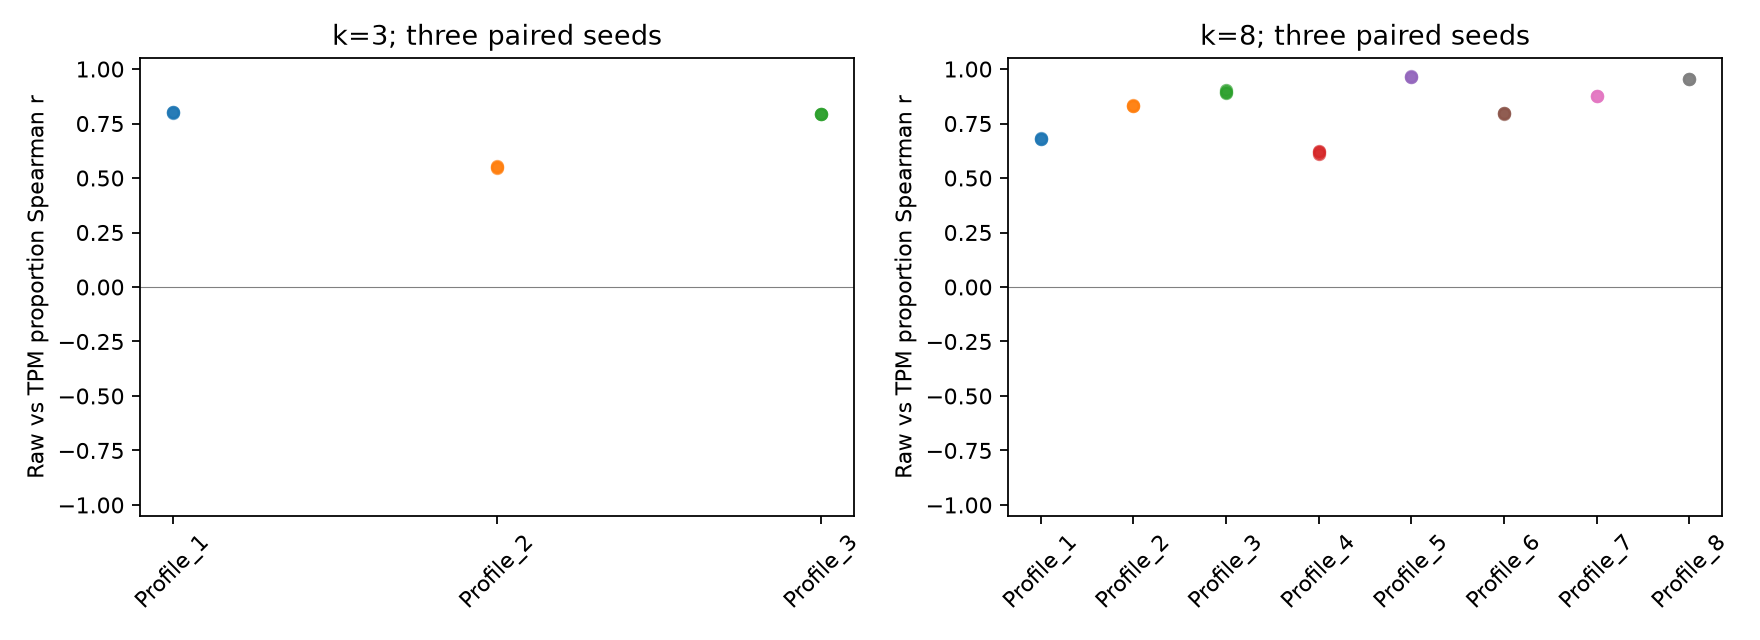

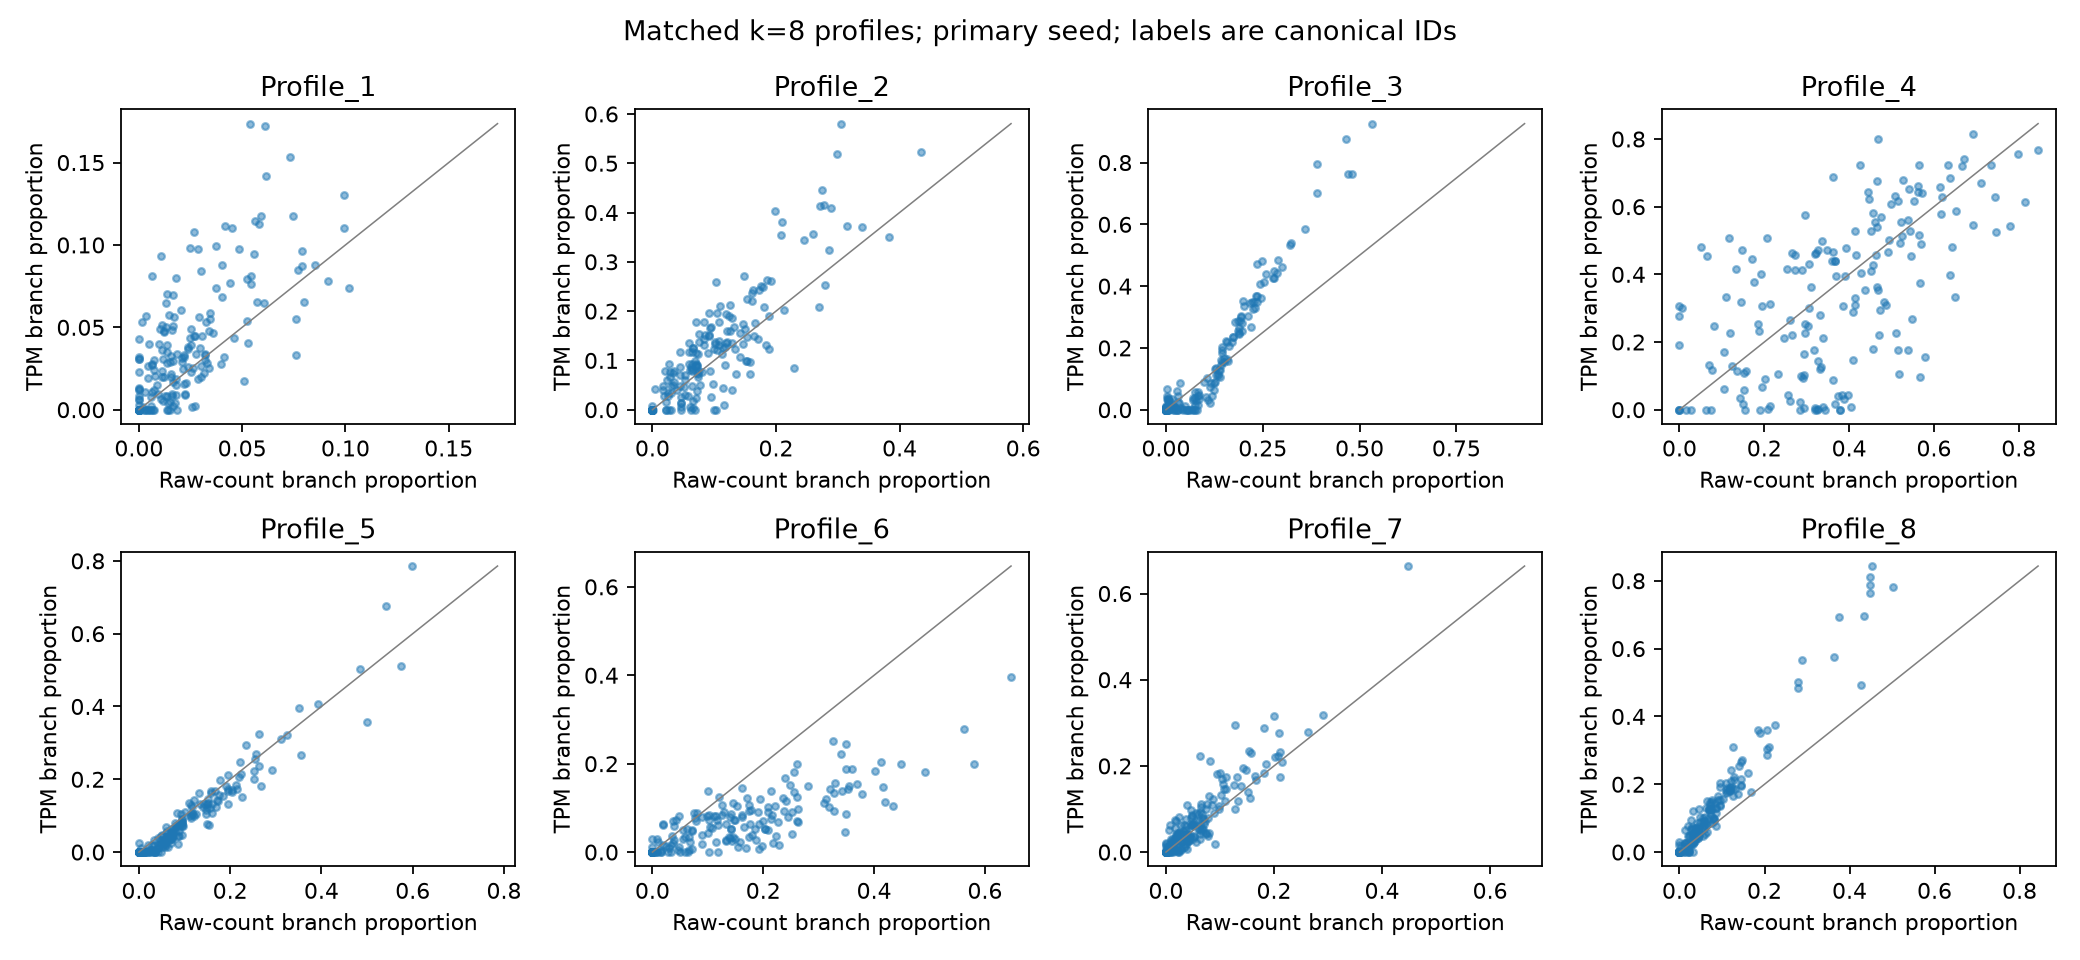

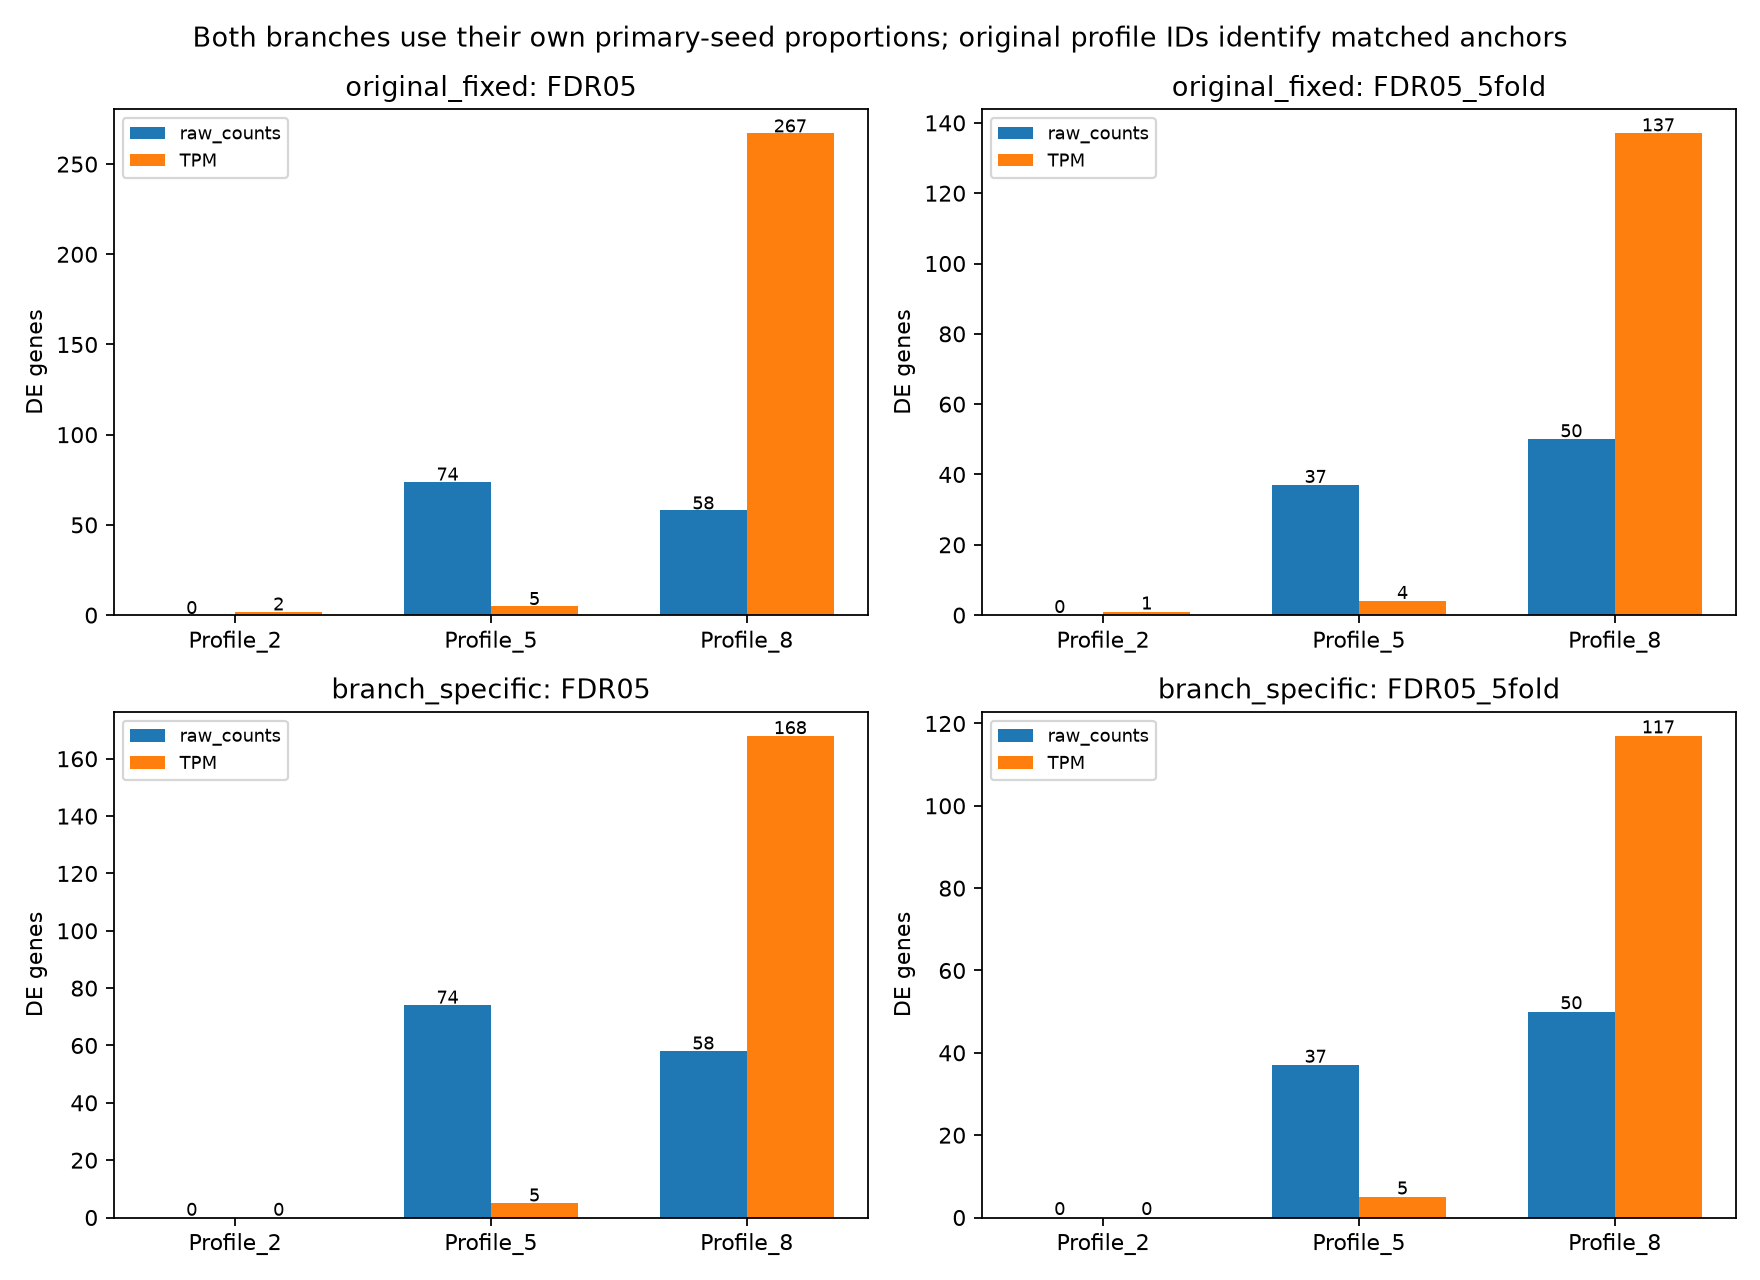

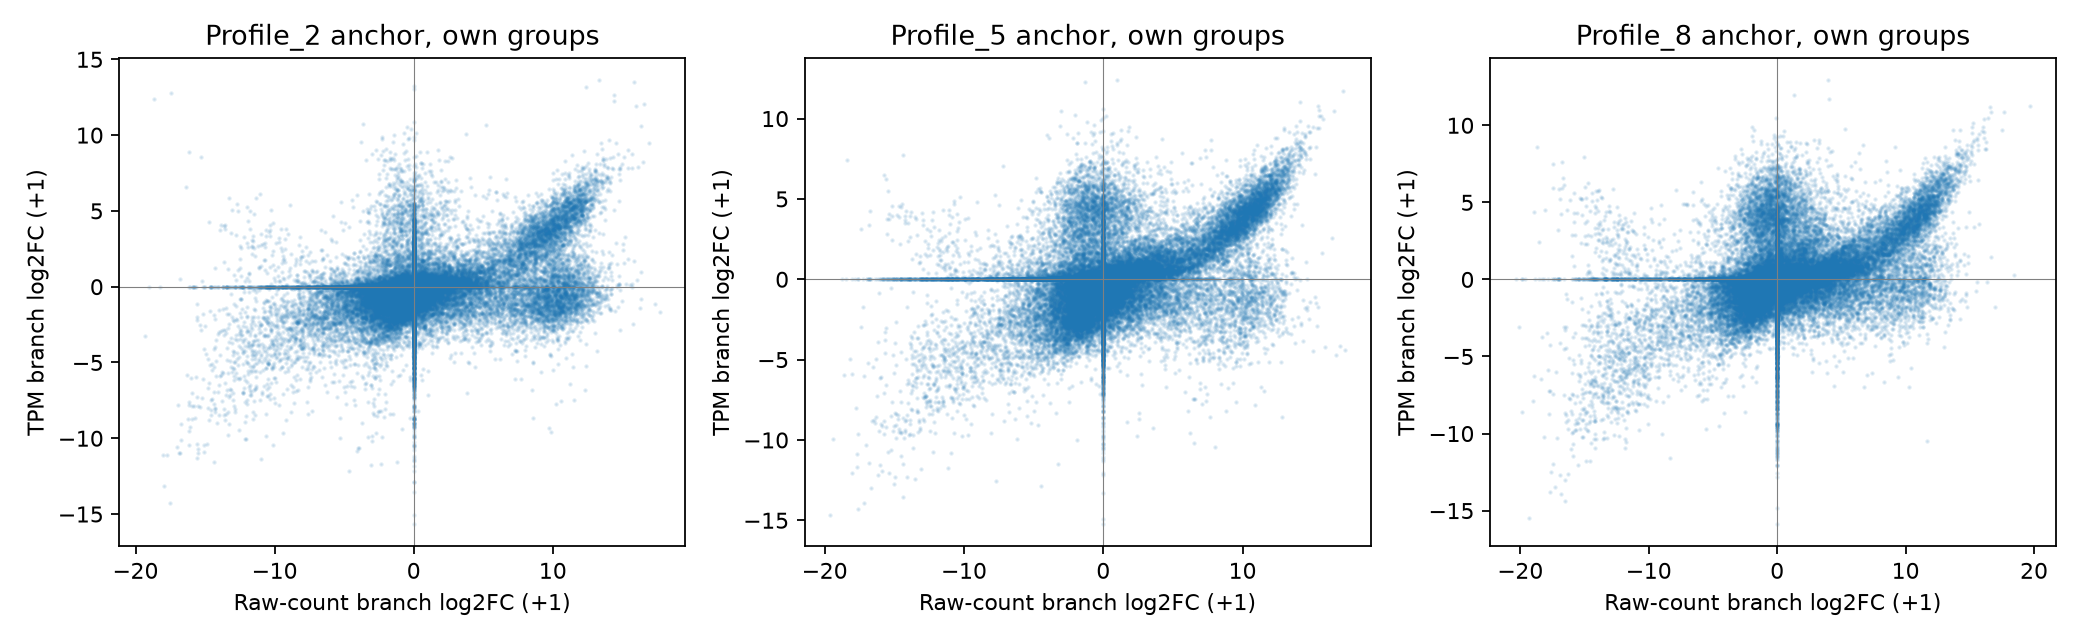